In [1]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import BytesIO
from astropy.io.votable import parse_single_table
from astropy.constants import h, e

import urllib3
urllib3.disable_warnings()

In [2]:
# To convert from frequency unit to eV
freq_to_eV = h.value/e.value
freq_to_eV

np.float64(4.135667696923859e-15)

## Source Name based SED extraction

In [3]:
#Choose your source
source_name = "MARKARIAN 421"
#source_name = "1ES 1727+502"

In [4]:
# get response from the url and convert it into astropy VO table.
url = "https://ned.ipac.caltech.edu/NED::API/PhotometryOfObject"
response = requests.get(url, params={ "TARGET": source_name, "SPECLINES": "no"}, timeout=60, verify=False)
table = parse_single_table(BytesIO(response.content)).to_table()

In [5]:
for col in table.columns.values():
    print(col.name, " : ", col.unit)
    print("    ", col.description)

row  :  None
     A row number applicable to this list only
phot_in_bandpass  :  None
     Bandpass at which the data were measured
phot_in_value  :  None
     Photometry value as published and interpreted by NED team
phot_in_upper_unc  :  None
     Photometry upper uncertainty as published and interpreted by NED team
phot_in_lower_unc  :  None
     Photometry lower uncertainty as published and interpreted by NED team
phot_in_unit  :  None
     Photometry unit as published and interpreted by NED team
sv_freq  :  Hz
     Frequency value as standardized by NED
sv_fluxd  :  Jy
     Flux density value as standardized by NED
sv_fluxd_pos_unc  :  Jy
     Upper uncertainty of flux density as standardized by NED
sv_fluxd_neg_unc  :  Jy
     Lower uncertainty of flux density as standardized by NED
sv_fluxd_upper_limit  :  Jy
     Upper limit of flux density as standardized by NED
sv_fluxd_lower_limit  :  Jy
     Lower limit of flux density as standardized by NED
sv_flux  :  Jy•Hz
     Flux valu

In [6]:
df = table.to_pandas()
df.head(3)

,row,phot_in_bandpass,phot_in_value,phot_in_upper_unc,phot_in_lower_unc,phot_in_unit,sv_freq,sv_fluxd,sv_fluxd_pos_unc,sv_fluxd_neg_unc,...,sv_flux_pos_unc,sv_flux_neg_unc,sv_flux_upper_limit,sv_flux_lower_limit,in_telescope,in_instrument,in_freq,in_freq_unit,in_aperture_type,phot_refcode
0,1,50 GeV-2 TeV (Fermi),3.290000e-10,2.720000e-11,2.720000e-11,erg/cm^2/s,2.480000e+26,1.326613e-13,1.096774e-14,1.096774e-14,...,2.720000e+12,2.720000e+12,NaN,NaN,Fermi,LAT,1.025,TeV,flux integrated from map or image,2016ApJS..222....5A
1,2,0.01-1 TeV (Fermi),4.370000e-10,1.860000e-11,1.860000e-11,erg/cm^2/s,1.220000e+26,3.581967e-13,1.524590e-14,1.524590e-14,...,1.860000e+12,1.860000e+12,NaN,NaN,Fermi,LAT,0.510,TeV,from fitting to map,2017ApJS..232...18A
2,3,100 MeV-100 GeV LAT,3.090000e-10,1.470000e-11,1.470000e-11,erg/cm^2/s,1.210000e+25,2.553719e-12,1.214876e-13,1.214876e-13,...,1.470000e+12,1.470000e+12,NaN,NaN,Fermi,LAT,50050.000,MeV,from fitting to map,2010ApJS..188..405A


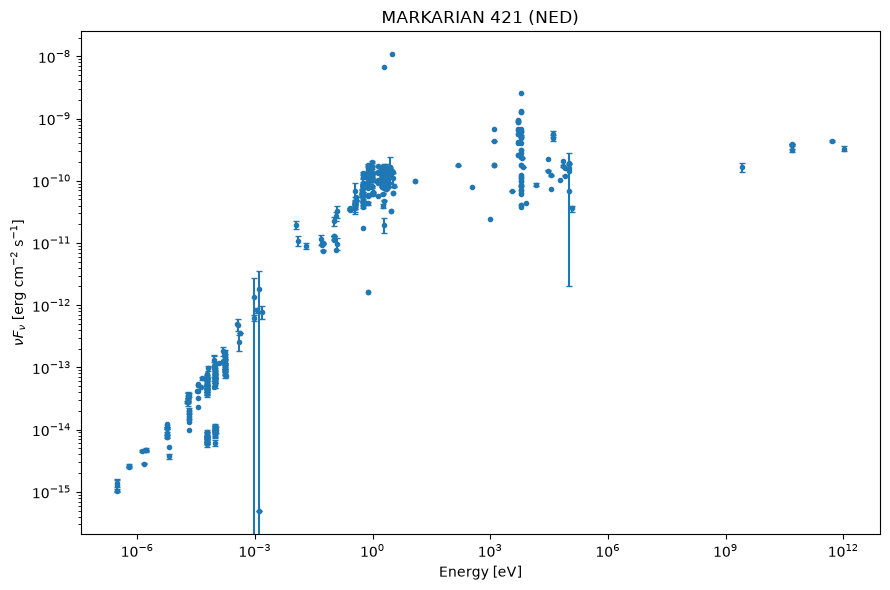

In [7]:
sed = df[(df["sv_freq"] > 0) & (df["sv_flux"] > 0)].copy()

# Jy Hz -> erg cm^-2 s^-1
sed["nuFnu"] = sed["sv_flux"] * 1e-23
sed["nuFnu_err_low"] = sed["sv_flux_neg_unc"] * 1e-23
sed["nuFnu_err_high"] = sed["sv_flux_pos_unc"] * 1e-23

sed["energy_eV"] = sed["sv_freq"] * freq_to_eV

plt.figure(figsize=(9, 6))
plt.errorbar(sed["energy_eV"], sed["nuFnu"], yerr=[sed["nuFnu_err_low"], sed["nuFnu_err_high"]], fmt="o", markersize=3, capsize=2)
plt.xscale("log")
plt.yscale("log")

plt.xlabel("Energy [eV]")
plt.ylabel(r"$\nu F_\nu$ [erg cm$^{-2}$ s$^{-1}$]")
plt.title(source_name+" (NED)")

plt.tight_layout()
plt.show()

### Saving to a CSV file 

In [8]:
output = sed[["energy_eV", "sv_freq", "nuFnu", "nuFnu_err_low", "nuFnu_err_high", "phot_in_bandpass", "in_telescope", "in_instrument", "phot_refcode"]].copy()
output.to_csv(source_name+"_NED_SED.csv", sep="\t", index=False)